# Clustering geometry, priors and rejected points

Compare centroid, full-covariance/variational mixture, Ward, spectral, DBSCAN and HDBSCAN clustering. Seven methods × three datasets × three seeds produce 63 fits. This is transductive analysis: full-data standardization/PCA uses all unlabeled examples. Labels are diagnostic only.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd() if Path("configs").exists() else Path.cwd().parent
sys.path.insert(0, str(root / "src"))


## Count priors and density decisions

Known cluster counts 3/3/10 are explicit priors for count-constrained families. Variational mixtures use a larger component cap; density methods determine count and noise. This difference prevents an unqualified claim of equal information budgets.

In [2]:
result = json.loads((root / "results/reference/unsupervised/metrics.json").read_text())
fits = pd.DataFrame(result["rows"])
assert len(fits) == 63
fits.groupby(["case", "method"])[["ari_all_points", "nonnoise_fraction", "clusters"]].mean().round(4)

ari_all_points  nonnoise_fraction  clusters
case             method                                                      
digits           agglomerative            0.6659             1.0000      10.0
                 dbscan                   0.1408             0.4274      16.0
                 gmm                      0.5254             1.0000      10.0
                 hdbscan                  0.1568             0.4135       7.0
                 kmeans                   0.4718             1.0000      10.0
                 spectral                 0.6833             1.0000      10.0
                 variational_gmm          0.6706             1.0000      20.0
variable_density agglomerative            0.9868             1.0000       3.0
                 dbscan                   0.7829             0.8560       6.0
                 gmm                      0.9934             1.0000       3.0
                 hdbscan                  0.8938             0.9380       3.0
                 kmeans                   0.8890             1.0000       3.0
                 spectral                 0.9447             1.0000       3.0
                 variational_gmm          0.9934             1.0000       3.0
wine             agglomerative            0.7899             1.0000       3.0
                 dbscan                   0.0280             0.0449       1.0
                 gmm                      0.8687             1.0000       3.0
                 hdbscan                  0.2630             0.6124       2.0
                 kmeans                   0.8975             1.0000       3.0
                 spectral                 0.9149             1.0000       3.0
                 variational_gmm          0.6702             1.0000       6.0

## Silhouette can reward selective rejection

Silhouette computed only on accepted points must be read with coverage. All-points ARI includes rejected points. PCA is a display, not the space in which Digits was clustered.

In [3]:
from sklearn.metrics import adjusted_rand_score
with np.load(root / "assets/source_data/clustering/digits.npz", allow_pickle=False) as values:
    truth = values["true_labels"]
    labels = values["hdbscan_0"]
    assert adjusted_rand_score(truth, labels) == fits.query("case == 'digits' and method == 'hdbscan' and seed == 0").ari_all_points.iloc[0]
    print("Accepted fraction:", (labels >= 0).mean(), "ARI:", adjusted_rand_score(truth, labels))

Accepted fraction: 0.41346688925987757 ARI: 0.15683923006731815


## Display the complete variable-density construction

The example intentionally has unequal densities. Compare every method rather than only a favorable subset. True labels were not used to choose density presets.

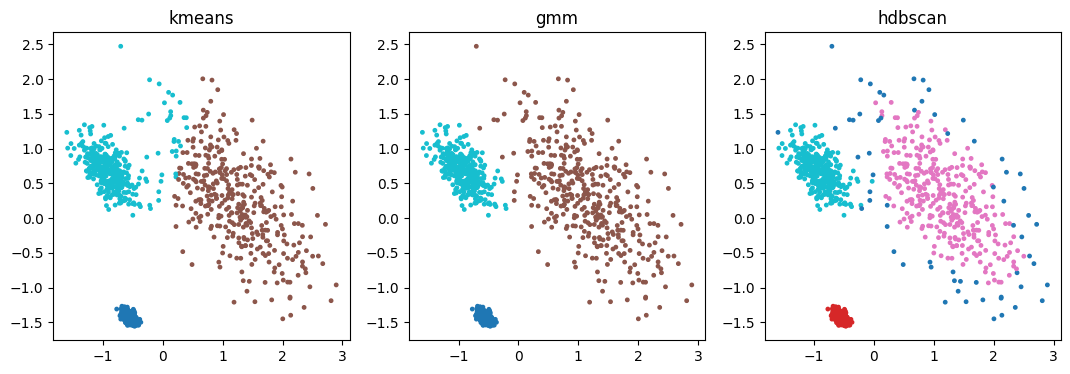

In [4]:
with np.load(root / "assets/source_data/clustering/variable_density.npz", allow_pickle=False) as values:
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, method in zip(axes, ["kmeans", "gmm", "hdbscan"]):
        ax.scatter(*values["projection"].T, c=values[method + "_0"], s=6, cmap="tab10")
        ax.set_title(method)
    plt.show()

## Separate fitting randomness from data robustness

Deterministic families repeat identical fits across seeds. A zero SD does not establish stability to resampling, feature noise, or a new population.

In [5]:
fits.groupby(["case", "method"])[["ari_all_points", "nonnoise_fraction"]].agg(["mean", "std"]).round(4)

ari_all_points         nonnoise_fraction     
                                           mean     std              mean  std
case             method                                                       
digits           agglomerative           0.6659  0.0000            1.0000  0.0
                 dbscan                  0.1408  0.0000            0.4274  0.0
                 gmm                     0.5254  0.0357            1.0000  0.0
                 hdbscan                 0.1568  0.0000            0.4135  0.0
                 kmeans                  0.4718  0.0082            1.0000  0.0
                 spectral                0.6833  0.0000            1.0000  0.0
                 variational_gmm         0.6706  0.0465            1.0000  0.0
variable_density agglomerative           0.9868  0.0000            1.0000  0.0
                 dbscan                  0.7829  0.0000            0.8560  0.0
                 gmm                     0.9934  0.0000            1.0000  0.0
                 hdbscan                 0.8938  0.0000            0.9380  0.0
                 kmeans                  0.8890  0.0000            1.0000  0.0
                 spectral                0.9447  0.0000            1.0000  0.0
                 variational_gmm         0.9934  0.0000            1.0000  0.0
wine             agglomerative           0.7899  0.0000            1.0000  0.0
                 dbscan                  0.0280  0.0000            0.0449  0.0
                 gmm                     0.8687  0.0203            1.0000  0.0
                 hdbscan                 0.2630  0.0000            0.6124  0.0
                 kmeans                  0.8975  0.0000            1.0000  0.0
                 spectral                0.9149  0.0000            1.0000  0.0
                 variational_gmm         0.6702  0.0711            1.0000  0.0

Reproduce with `python scripts/run_clustering.py`; verify and report with `python scripts/report_clustering.py`. Read [clustering results](../docs/clustering_results.md) and [the interactive projection](../docs/explorer.html).